In [2]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Definir arquitetura (Padrão Keras)
modelo_tf = models.Sequential([
    # Camada de entrada
    layers.Input(shape=(2,)),
    # Camada oculta 1: 32 neurônios com ativação ReLU
    layers.Dense(32, activation="relu"),
    # Camada oculta 2: 16 neurônios com ativação ReLU
    layers.Dense(16, activation="relu"),
    # Camada de saída: 1 neurônio com ativação Sigmoid para probabilidade binária
    layers.Dense(1, activation="sigmoid")
])

# Exibir o resumo estrutural da rede
modelo_tf.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 32)             │            96 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 641 (2.50 KB)

 Trainable params: 641 (2.50 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
modelo_tf.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.01),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [7]:
import time
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

# Gera 1000 amostras com formato de duas luas
X, y = make_moons(n_samples=1000, noise=0.25, random_state=42)

# Divião entre treino (70%) e teste (30%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

In [14]:
historico = modelo_tf.fit(
    X_train, y_train,                       # ✅ treino com y_train
    epochs=400,
    batch_size=32,
    validation_data=(X_test, y_test),       # ✅ validação explícita no teste
    verbose=1
)

# Avaliação final no conjunto de teste
loss_teste, acc_teste = modelo_tf.evaluate(X_test, y_test, verbose=0)
print(f"Acurácia final no TensorFlow: {acc_teste * 100:.2f}%")

Epoch 1/400
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9400 - loss: 0.1367 - val_accuracy: 0.9500 - val_loss: 0.1213
Epoch 2/400
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9386 - loss: 0.1368 - val_accuracy: 0.9500 - val_loss: 0.1239
Epoch 3/400
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9386 - loss: 0.1368 - val_accuracy: 0.9533 - val_loss: 0.1225
Epoch 4/400
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9386 - loss: 0.1367 - val_accuracy: 0.9500 - val_loss: 0.1227
Epoch 5/400
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9400 - loss: 0.1370 - val_accuracy: 0.9533 - val_loss: 0.1209
Epoch 6/400
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9414 - loss: 0.1360 - val_accuracy: 0.9533 - val_loss: 0.1224
Epoch 7/400
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9400 - loss: 0.1365 - val_accuracy: 0.9533 - val_loss: 0.1216
Epoch 8/400
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9400 - loss: 0.1365 - val_accuracy: 0.9500 - v

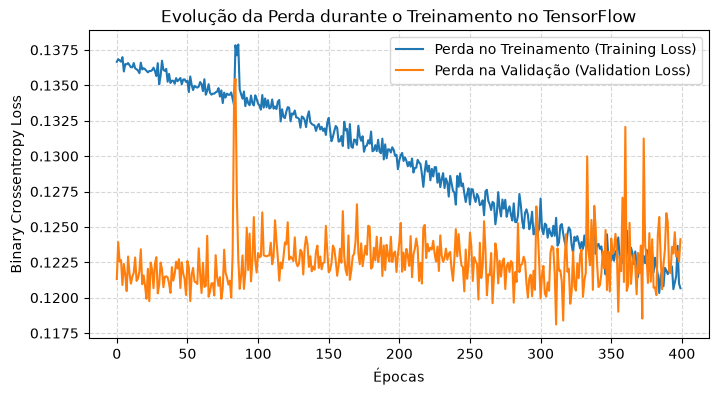

In [15]:
import matplotlib.pylab as plt

plt.figure(figsize=(8, 4))
plt.plot(historico.history["loss"], label="Perda no Treinamento (Training Loss)")
plt.plot(historico.history["val_loss"], label="Perda na Validação (Validation Loss)")
plt.title("Evolução da Perda durante o Treinamento no TensorFlow")
plt.xlabel("Épocas")
plt.ylabel("Binary Crossentropy Loss")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

In [19]:
from pathlib import Path

# Garante a existência da pasta models
Path("models").mkdir(exist_ok=True)

caminho_modelo_tf = "models/modelo_mlp_tensorflow.keras"
modelo_tf.save(caminho_modelo_tf)              # ✅ salva de verdade
print(f"Modelo do TensorFlow salvo com sucesso em: {caminho_modelo_tf}")

Modelo do TensorFlow salvo com sucesso em: models/modelo_mlp_tensorflow.keras


In [21]:
import numpy as np

# Carrega o modelo compilado do disco (mesmo caminho usado no save)
modelo_api = tf.keras.models.load_model("models/modelo_mlp_tensorflow.keras")  # ✅ com a pasta

novos_dados = np.array([
    [0.4, 0.1],
    [-0.3, 0.7]
])

probabilidades = modelo_api.predict(novos_dados)
classes_previstas = (probabilidades >= 0.5).astype(int).flatten()

for i, (classe, prob) in enumerate(zip(classes_previstas, probabilidades.flatten())):
    print(f"Requisição {i+1}: Classe = {classe} | Probabilidade = {prob * 100:.2f}%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
Requisição 1: Classe = 1 | Probabilidade = 90.56%
Requisição 2: Classe = 0 | Probabilidade = 0.09%
